In [1]:
import numpy as np
import matplotlib.pyplot as plt
from importlib import resources
import pymatreader as pmr

# =========================================================================
# 1. OPTIMIZED ENGINE INITIALIZATION (RUNS ONCE IN RAM)
# =========================================================================
def load_machine_data(file_path=resources.files("pyRadPlan.data.machines").joinpath("protons_Generic.mat")):
    """Loads the binary machine lookup tables once into RAM memory."""
    mat_dict = pmr.read_mat(file_path)
    machine_root = mat_dict['machine'] if 'machine' in mat_dict else mat_dict
    return machine_root['data']

GLOBAL_DATA_BLOCK = load_machine_data()


# =========================================================================
# 2. INTERNAL UTILITY SUB-FUNCTIONS
# =========================================================================
def _convert_hu_to_rsp(hu_block):
    exact_hu_nodes  = [-1000.0, -950.0, -120.0,   0.0,   100.0,   200.0,  1000.0,  2000.0,  3000.0]
    exact_rsp_nodes = [   0.00,   0.05,   0.88,  1.00,    1.05,    1.10,    1.47,    1.83,    2.17]
    return np.interp(hu_block, exact_hu_nodes, exact_rsp_nodes)

def _convert_ct_to_wepl(hu_block, voxel_size_mm):
    rsp_grid = _convert_hu_to_rsp(hu_block)
    return np.cumsum(rsp_grid * voxel_size_mm, axis=0)


# =========================================================================
# 3. UNIFIED PENCIL BEAM PREDICTION MASTER FUNCTION WITH DIAGNOSTIC SUITE
# =========================================================================
def predict_pencil_beam_dose(
    ct_hu_grid, 
    energy_mev=150.0, 
    cy=None, 
    cz=None, 
    voxel_size_mm=1.0, 
    sigma_init_mm=None,
    if_check=0,
    data_block=GLOBAL_DATA_BLOCK
):
    """
    Computes the 3D physical dose grid for a single proton pencil beam entering 
    along Axis 0. Replicates the core physics engine of pyRadPlan / matRad.
    
    Parameters:
        ct_hu_grid:    3D NumPy array containing Hounsfield Units (HU) of the anatomy.
        energy_mev:    Nominal energy of the proton beam.
        cy, cz:        Central axis coordinates on the transverse plane. Defaults to the absolute center.
        voxel_size_mm: Spatial calibration scaling size (mm). Defaults to 1.0 mm.
        sigma_init_mm: Initial beam spotlight focus standard deviation at surface (in mm).
        if_check:      If set to 1, renders diagnostic profile panels with the beam entering from the left.
        data_block:    Pre-loaded memory reference table to bypass disk I/O.
    """
    nx, ny, nz = ct_hu_grid.shape
    
    # Resolve coordinate centering configurations
    if cy is None: cy = ny // 2
    if cz is None: cz = nz // 2
        
    # Locate the target energy channel index in the lookup tables
    available_energies = np.array(data_block['energy'])
    energy_idx = np.argmin(np.abs(available_energies - energy_mev))
    
    # Extract reference tracking profiles for this channel
    ref_depths = np.array(data_block['depths'][energy_idx])
    target_dose_curve = np.array(data_block['Z'][energy_idx])
    ref_sigmas = np.array(data_block['sigma'][energy_idx])
    
    # Decide initial beam size following authors' default strategy if not specified
    if sigma_init_mm is None:
        target_focus = data_block['initFocus'][energy_idx]
        fwhm_at_iso = target_focus['SisFWHMAtIso']
        sigma_init_mm = fwhm_at_iso / (2.0 * np.sqrt(2.0 * np.log(2.0)))
        
    # Execution Step 1: Generate 3D WEPL Paths
    wepl_grid = _convert_ct_to_wepl(ct_hu_grid, voxel_size_mm)
    flat_wepl = wepl_grid.flatten()
    
    # Execution Step 2: Task 1 - Longitudinal Depth Dose Interpolation
    flat_ddd_dose = np.interp(flat_wepl, ref_depths, target_dose_curve, left=0.0, right=0.0)
    task1_dose_grid = flat_ddd_dose.reshape(ct_hu_grid.shape)
    
    # Execution Step 3: Task 2 - Lateral Gaussian Beam Spreading
    flat_sigmas = np.interp(flat_wepl, ref_depths, ref_sigmas, left=ref_sigmas[0], right=ref_sigmas[-1])
    sigma_scatter_grid = flat_sigmas.reshape(ct_hu_grid.shape)
    sigma_total_grid = np.sqrt(sigma_scatter_grid**2 + sigma_init_mm**2)
    
    # Spatial Cross-Section Configuration
    y_indices = np.arange(ny)
    z_indices = np.arange(nz)
    Y, Z = np.meshgrid(y_indices, z_indices, indexing='ij')
    
    r_squared = (Y - cy)**2 + (Z - cz)**2
    r_squared_3d = r_squared[np.newaxis, :, :]
    
    gaussian_stencil = np.exp(-0.5 * r_squared_3d / (sigma_total_grid**2)) / (2.0 * np.pi * (sigma_total_grid**2))
    final_3d_dose = task1_dose_grid * gaussian_stencil
    
    # ---------------------------------------------------------------------
    # DIAGNOSTIC VISUALIZATION BLOCK (IF_CHECK SUITE)
    # ---------------------------------------------------------------------
    if if_check == 1:
        # Extract profiles intersecting right through our active beam axis coordinates
        ct_slice = ct_hu_grid[:, :, cz].T
        task1_slice = task1_dose_grid[:, :, cz].T
        final_slice = final_3d_dose[:, :, cz].T
        
        fig, axes = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True)
        
        # Panel 1: CT Anatomy Context
        im0 = axes[0].imshow(ct_slice, cmap='bone', aspect='auto')
        axes[0].set_title(f"1. Patient CT Geometry Context (Transverse Slice at Z={cz})")
        axes[0].set_ylabel("Height Index (Y)")
        fig.colorbar(im0, ax=axes[0], label="HU Numbers")
        
        # Panel 2: Task 1 Line-Needle Dose Profile
        im1 = axes[1].imshow(task1_slice, cmap='viridis', aspect='auto')
        axes[1].set_title("2. Task 1: Infinite Needle Longitudinal Dose Grid (No Lateral Spread)")
        axes[1].set_ylabel("Height Index (Y)")
        fig.colorbar(im1, ax=axes[1], label="Relative Dose")
        
        # Panel 3: Final Physical Scattered Pencil Beam
        # Capping at the 98.5th percentile preserves deep structure visibility from scaling skew
        v_max_cap = np.percentile(final_slice, 98.5) if np.max(final_slice) > 0 else 1.0
        im2 = axes[2].imshow(final_slice, cmap='viridis', aspect='auto', vmax=v_max_cap)
        axes[2].set_title(f"3. Final Physical 3D Dose Matrix (With Multiple Coulomb Scattering, Center: {cy})")
        axes[2].set_ylabel("Height Index (Y)")
        axes[2].set_xlabel("Depth Axis (Axis 0 - Beam Entering from Left)")
        fig.colorbar(im2, ax=axes[2], label="Physical Dose Intensity")
        
        plt.tight_layout()
        plt.show()
        
    return final_3d_dose


ModuleNotFoundError: No module named 'pymatreader'

SyntaxError: invalid syntax (4119613346.py, line 1)

In [2]:
# 3. SET UP INTENDED USER PHANTOM ENVIRONMENT (300 x 48 x 48)
shape = (300, 48, 48)
Energy_this = 150 

# Baseline defined entirely as uniform muscle/water tissue (0 HU)
ct_hu_phantom = np.zeros(shape, dtype=float)

# Impose an air gap entrance (-1000 HU) at the beginning of the ray field
ct_hu_phantom[0:15, :, :] = -1000.0

# Position a dense cortical bone mass block (1500 HU) inside the track
ct_hu_phantom[120:200, 24:, 15:] = 1500.0


# 4. PROCESS THROUGH THE PIPELINE
voxel_thickness = 1.0  # 1 mm step resolution
# wepl_matrix = convert_ct_to_wepl(ct_hu_phantom, voxel_size_mm=1.0)
# task1_dose_grid = look_up_repository_ddd(wepl_matrix, energy_mev=Energy_this)
# final_physical_dose = apply_lateral_spreading(wepl_matrix, task1_dose_grid, energy_mev=Energy_this)



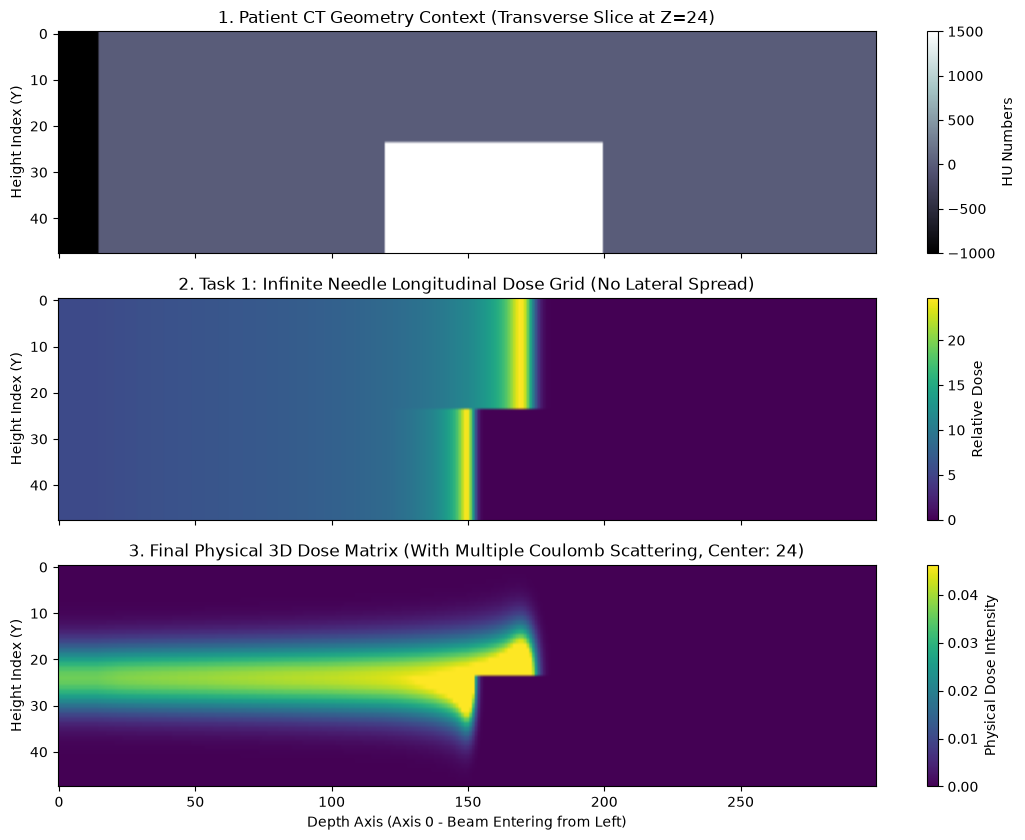

In [3]:
dose_default = predict_pencil_beam_dose(ct_hu_phantom, energy_mev=150.0, if_check=1)

In [4]:
# Load the exact reference validation phantom provided by the developers
tg119_file_path = resources.files("pyRadPlan.data.phantoms").joinpath("TG119.mat")
tg119_data = pmr.read_mat(tg119_file_path)

# Extract the Hounsfield Unit (HU) scan volume
# This provides the true clinical 3D matrix to compare against your mock phantoms
ct_volume_author = tg119_data['ct']['cube'] 
print("Official Reference CT Matrix Shape:", ct_volume_author.shape)

Official Reference CT Matrix Shape: (167, 167, 129)


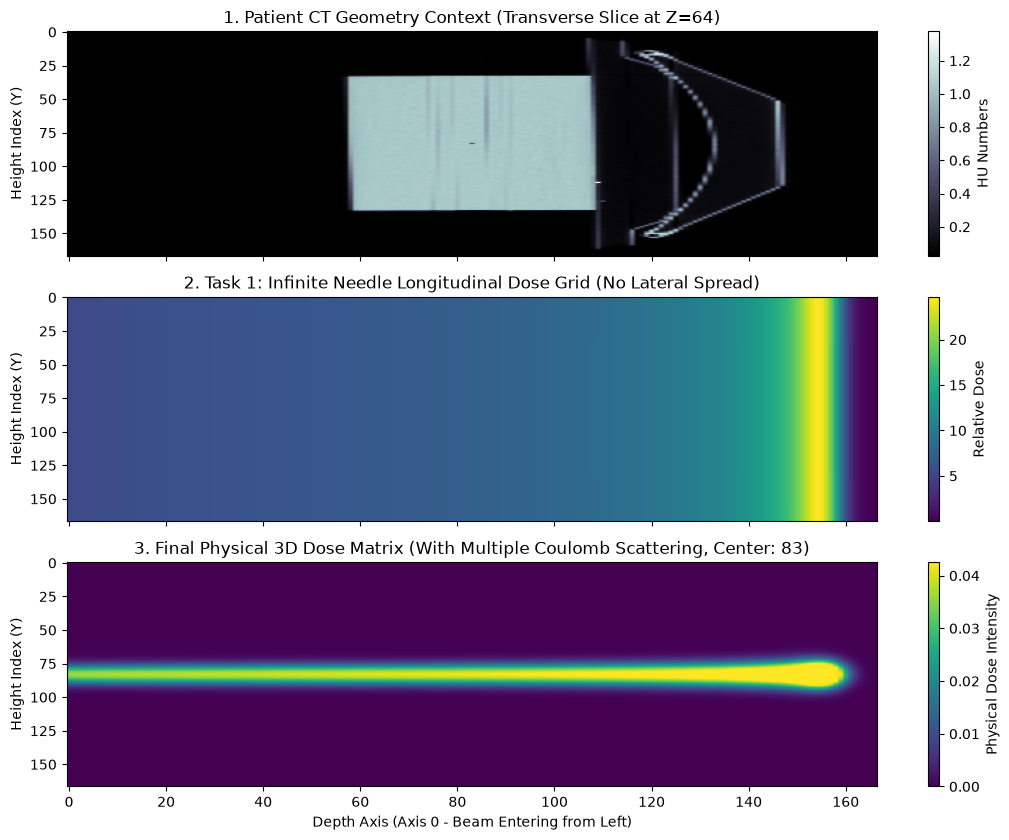

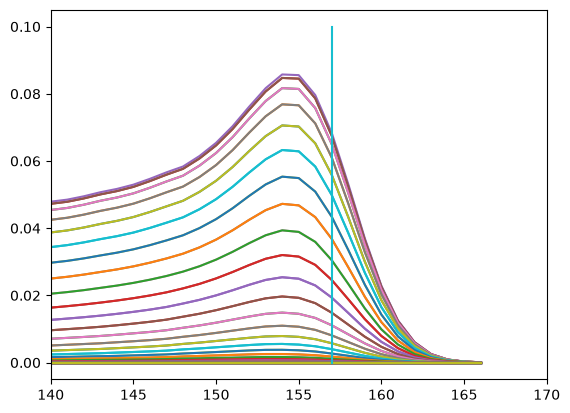

In [8]:
my_calculated_tg119_dose = predict_pencil_beam_dose(
    ct_volume_author, 
    energy_mev=150.0, 
    if_check=1 # Set to 1 to inspect the structural alignment panels visually
)
plt.figure()
# ~ ~157 mm
plt.plot(my_calculated_tg119_dose[:,80,:])
plt.xlim([140,170])
plt.plot([157,157],[0,0.1])
